<a href="https://colab.research.google.com/github/jeevithajeevitha3420-create/Data-Science/blob/main/Task_2_DS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv("student_performance_dataset.csv")
print(df.shape)
df.head()

(612, 9)


,studytime,attendance,Medu,internet,activities,failures,absences,previous_score,final_score
0,3,97.5,2.0,yes,no,0,6,9.5,13.6
1,2,82.5,2.0,no,yes,0,9,15.7,15.3
2,3,88.6,NaN,yes,yes,0,5,13.8,15.4
3,2,60.9,2.0,yes,yes,2,5,10.1,10.5
4,1,73.4,3.0,yes,no,0,3,14.0,13.9


In [ ]:
df.info()
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print(df["internet"].unique(), df["activities"].unique())
print(df["attendance"].describe())      # max is above 100, so something is wrong

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   studytime       612 non-null    int64  
 1   attendance      586 non-null    float64
 2   Medu            592 non-null    float64
 3   internet        612 non-null    object 
 4   activities      612 non-null    object 
 5   failures        612 non-null    int64  
 6   absences        612 non-null    int64  
 7   previous_score  597 non-null    float64
 8   final_score     612 non-null    float64
dtypes: float64(4), int64(3), object(2)
memory usage: 43.2+ KB
studytime          0
attendance        26
Medu              20
internet           0
activities         0
failures           0
absences           0
previous_score    15
final_score        0
dtype: int64
Duplicates: 12
['yes' 'no' 'YES' 'NO'] ['no' 'yes' ' Yes' ' No']
count    586.000000
mean      84.860922
std       11.250320
min       4

In [ ]:
df = df.drop_duplicates()

for c in ["internet", "activities"]:
    df[c] = df[c].str.strip().str.lower()

df.loc[df["attendance"] > 100, "attendance"] = np.nan    # impossible values become missing

for c in ["attendance", "previous_score", "Medu"]:
    df[c] = df[c].fillna(df[c].median())
df["Medu"] = df["Medu"].astype(int)

print(df.isna().sum().sum(), len(df))     # expect 0 and 600

0 600


In [ ]:
num = ["studytime", "attendance", "previous_score", "Medu", "failures", "absences", "final_score"]
print(df[num].describe().round(2))
print(df[num].corr()["final_score"].sort_values(ascending=False).round(3))

print(df.groupby("studytime")["final_score"].mean().round(2))
print(df.groupby("internet")["final_score"].mean().round(2))
print(df.groupby("activities")["final_score"].mean().round(2))
print(df.groupby("Medu")["final_score"].mean().round(2))

       studytime  attendance  previous_score    Medu  failures  absences  \
count     600.00      600.00          600.00  600.00    600.00    600.00   
mean        2.12       84.32           12.54    2.72      0.31      4.87   
std         0.90        9.32            2.38    1.06      0.70      2.33   
min         1.00       48.50            5.20    0.00      0.00      0.00   
25%         1.00       78.70           10.90    2.00      0.00      3.00   
50%         2.00       84.90           12.50    3.00      0.00      5.00   
75%         3.00       90.32           14.12    4.00      0.00      6.00   
max         4.00      100.00           20.00    4.00      3.00     13.00   

       final_score  
count       600.00  
mean         14.31  
std           2.62  
min           5.90  
25%          12.70  
50%          14.40  
75%          15.90  
max          20.00  
final_score       1.000
previous_score    0.819
studytime         0.496
Medu              0.262
attendance        0.249
absenc

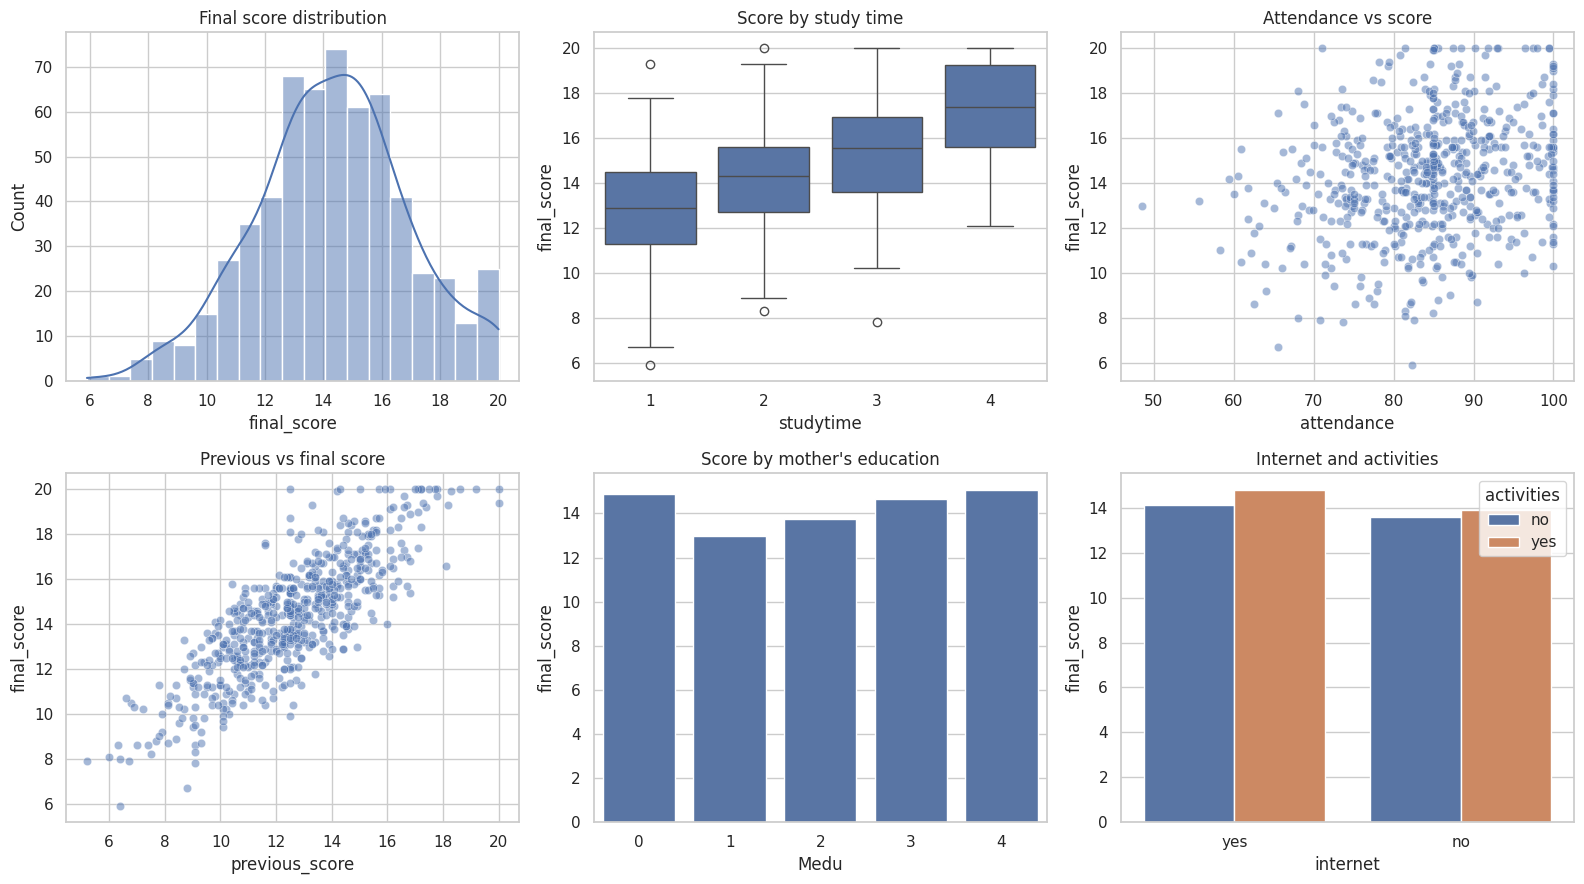

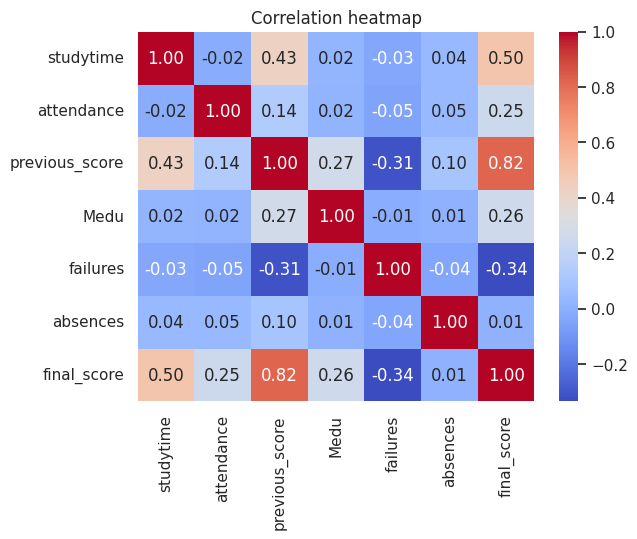

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
sns.histplot(df["final_score"], kde=True, ax=ax[0, 0]).set(title="Final score distribution")
sns.boxplot(x="studytime", y="final_score", data=df, ax=ax[0, 1]).set(title="Score by study time")
sns.scatterplot(x="attendance", y="final_score", data=df, alpha=0.5, ax=ax[0, 2]).set(title="Attendance vs score")
sns.scatterplot(x="previous_score", y="final_score", data=df, alpha=0.5, ax=ax[1, 0]).set(title="Previous vs final score")
sns.barplot(x="Medu", y="final_score", data=df, errorbar=None, ax=ax[1, 1]).set(title="Score by mother's education")
sns.barplot(x="internet", y="final_score", hue="activities", data=df, errorbar=None, ax=ax[1, 2]).set(title="Internet and activities")
plt.tight_layout(); plt.show()

sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()

            Model   MAE  RMSE    R2  CV_R2
Linear Regression 1.168 1.455 0.668  0.747
            Ridge 1.167 1.455 0.668  0.747
Gradient Boosting 1.222 1.512 0.641  0.705
    Random Forest 1.301 1.584 0.606  0.695
    Decision Tree 1.385 1.695 0.549  0.609


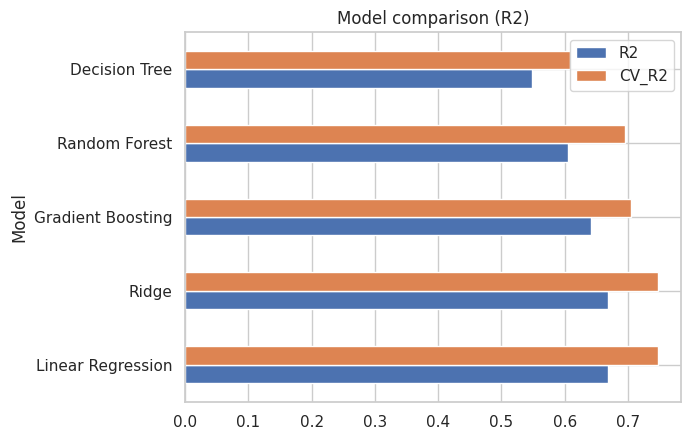

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop(columns="final_score"); y = df["final_score"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)

cat_cols = ["internet", "activities"]
num_cols = [c for c in X.columns if c not in cat_cols]
pre = ColumnTransformer([("num", StandardScaler(), num_cols),
                         ("cat", OneHotEncoder(drop="first"), cat_cols)])

models = {"Linear Regression": LinearRegression(), "Ridge": Ridge(alpha=1.0),
          "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
          "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
          "Gradient Boosting": GradientBoostingRegressor(random_state=42)}

rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)]).fit(Xtr, ytr)
    pred = pipe.predict(Xte); fitted[name] = pipe
    cv = cross_val_score(Pipeline([("pre", pre), ("model", m)]), X, y, cv=5, scoring="r2").mean()
    rows.append({"Model": name, "MAE": mean_absolute_error(yte, pred),
                 "RMSE": mean_squared_error(yte, pred) ** 0.5,
                 "R2": r2_score(yte, pred), "CV_R2": cv})

results = pd.DataFrame(rows).round(3).sort_values("R2", ascending=False)
print(results.to_string(index=False))
results.set_index("Model")[["R2", "CV_R2"]].plot.barh(title="Model comparison (R2)"); plt.show()

previous_score    0.826
studytime         0.097
attendance        0.051
absences          0.018
Medu              0.018
internet          0.015
failures          0.006
activities        0.005
dtype: float64


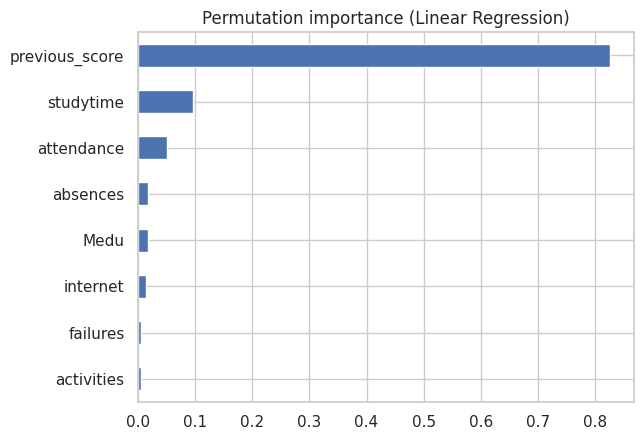

In [ ]:
from sklearn.inspection import permutation_importance

best = results.iloc[0]["Model"]
pi = permutation_importance(fitted[best], Xte, yte, n_repeats=15, random_state=42)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values()
print(imp.sort_values(ascending=False).round(3))
imp.plot.barh(title=f"Permutation importance ({best})"); plt.show()